# Extração de características visuais e filtros convolucionais

- **Repositório:** `visao-computacional-ocr`  
- **Tecnologias:** OpenCV, TensorFlow  
- **Arquivo Original:** `2025-2-BCC-VC.ipynb`  

---


# Report - Computer Vision


## Bachelor's Degree in Computer Science / PUCPR

**Prof. Rayson Laroca**

Renan Antonio Hammerschmidt Krefta - renan.krefta@pucpr.edu.br

Victor Silva Camargo - victor.camargo1@pucpr.edu.br

Vinícius Silva Camargo - vinicius.camargo1@pucpr.edu.br


2025

# Import the libs you need

In [1]:
# Import all packages you need here
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
import pandas as pd
import seaborn as sns
import os
from PIL import Image, ImageEnhance
from skimage.feature import local_binary_pattern
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
# Importar o RandomForestClassifier em vez de SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Add others as needed (scikit-learn, TensorFlow/PyTorch, etc.)

# 1. Define the task and dataset

In this section:
- Clearly define the chosen task;
- Provide a description and link to the dataset;
- Justify your choice and ensure dataset is archived for final submission;
- If task ≠ image classification (detection, segmentation, OCR, etc.), explain how you will simplify Step 6 (traditional baseline).

### 1. Definição da Tarefa

A tarefa escolhida para este projeto é a **classificação de imagens de doenças oculares**. O objetivo principal é desenvolver um modelo de aprendizado de máquina capaz de analisar uma imagem da retina e classificá-la automaticamente em uma de quatro categorias distintas: **Catarata**, **Retinopatia Diabética**, **Glaucoma** ou **Normal** (olho saudável).

### 2. Descrição e Link do Dataset

Para a execução desta tarefa, será utilizado o conjunto de dados público **"Eye Diseases Classification"**, disponível na plataforma Kaggle.

* **Link para o dataset:** `https://www.kaggle.com/datasets/gunavenkatdoddi/eye-diseases-classification`

Este dataset é composto por um total de 4.217 imagens coloridas da retina, divididas entre as quatro classes de interesse. A distribuição das imagens é relativamente balanceada entre as categorias:
* **Catarata:** 1038 imagens
* **Retinopatia Diabética:** 1098 imagens
* **Glaucoma:** 1007 imagens
* **Normal:** 1074 imagens

As imagens possuem diferentes resoluções e foram capturadas sob diversas condições, o que torna o dataset robusto e adequado para treinar um modelo generalizável para um cenário do mundo real.

### 3. Justificativa da Escolha

A escolha deste dataset e da tarefa se justifica pela alta relevância clínica e social do diagnóstico precoce de doenças oculares, que podem levar à perda de visão se não tratadas.

O dataset **"Eye Diseases Classification"** é uma referência no âmbito da oftalmologia diagnóstica por imagem, sendo amplamente utilizado em periódicos e artigos científicos. Sua utilização permite não apenas desenvolver uma solução prática, mas também comparar a performance do modelo desenvolvido com outros resultados já publicados na literatura, servindo como um *benchmark* para avaliar a eficácia de novas técnicas de classificação.

# 2. Acquire the dataset

In this section, **load the dataset** and carry out **initial processing** to ensure that data types are properly formatted for subsequent steps. The exact procedure may vary depending on how the data is acquired (e.g., directly from files or through well-known APIs) and also on how further steps will be conducted.

**Important note**: if the dataset is excessively large or contains high-resolution images, **consider subsampling and/or resizing the images to a manageable size** to ensure computational feasibility — especially when using limited resources such as Google Colab.

* Clearly justify the chosen subsampling strategy and confirm that the resulting data remains representative of the original dataset;
* *This subsampling step may be conducted after "Dataset analysis and visualization" if you find it more adequate*.

In [2]:
# use as many code and text cells as needed
!git clone https://github.com/VictorSilvaCamargo/eye_diseases_dataset.git

fatal: destination path 'eye_diseases_dataset' already exists and is not an empty directory.


# 3. Dataset analysis and visualization

In this section, you should conduct a comprehensive analysis of the dataset, reporting on (but not limited to) the following aspects:

- **Basic statistics:**
  - Total number of images;
  - Range and distribution of image resolutions;
  - Number of classes.

- **Class distribution:**
  - Visualize with plots/histograms;
  - Discuss potential **impacts of class imbalance** on model performance (e.g., bias toward majority classes).

- **Examples:**
  - Display representative samples from each class to illustrate dataset diversity and possible challenges (e.g., intra-class variation, inter-class similarity).

- **Dataset splits:**
  - If train/validation/test splits are already defined by the dataset authors, clearly describe them;
  - If not, proceed to the next section (Step 4) where you will define and justify your splitting strategy.

- **Data quality assessment:**
  - Comment on factors such as blur, occlusions, illumination issues, noise, and mislabeled or ambiguous samples;
  - Relate these observations to the **specific problem** being addressed (e.g., misclassification due to low resolution, object detection under motion blur, OCR legibility, etc.).

- **Specialized tasks:**
  - For **detection or segmentation** datasets, analyze spatial properties of the annotations, including object **sizes, locations, aspect ratios**, and potential edge cases.

In [3]:
# use as many code and text cells as needed
# Diretório base do dataset
diretorio_dataset = '/content/eye_diseases_dataset'

# Lista todos os caminhos das imagens e cria um DataFrame
caminhos_imagens = []
rotulos = []
for nome_classe in os.listdir(diretorio_dataset):
    diretorio_classe = os.path.join(diretorio_dataset, nome_classe)
    if os.path.isdir(diretorio_classe):
        for nome_arquivo in os.listdir(diretorio_classe):
            if nome_arquivo.endswith(('.jpg', '.jpeg', '.png')):
                caminhos_imagens.append(os.path.join(diretorio_classe, nome_arquivo))
                rotulos.append(nome_classe)

df = pd.DataFrame({'caminho_arquivo': caminhos_imagens, 'rotulo': rotulos})

print("DataFrame principal criado com sucesso!")

# Estatísticas básicas
print("\n--- Estatísticas Básicas do Dataset ---")
print(f"Número total de imagens: {len(df)}")
print(f"Número de classes: {df['rotulo'].nunique()}")

# Distribuição das classes
print("\n--- Distribuição das Classes ---")
display(df['rotulo'].value_counts())

# Analisar resoluções das imagens (Pode levar algum tempo para datasets grandes)
print("\n--- Análise da Resolução das Imagens ---")
resolucoes_imagens = []
for caminho_img in df['caminho_arquivo']:
    try:
        img = plt.imread(caminho_img)
        resolucoes_imagens.append(img.shape[:2]) # Obtém (altura, largura)
    except Exception as e:
        print(f"Não foi possível ler a imagem {caminho_img}: {e}")

df_resolucoes = pd.DataFrame(resolucoes_imagens, columns=['altura', 'largura'])
print(f"Número de imagens com dados de resolução: {len(df_resolucoes)}")

if not df_resolucoes.empty:
    print("\nDistribuição das resoluções:")
    display(df_resolucoes.value_counts().head()) # Exibe as resoluções mais comuns
    print("\nIntervalo de resoluções (Altura x Largura):")
    print(f"Altura Mínima: {df_resolucoes['altura'].min()}, Altura Máxima: {df_resolucoes['altura'].max()}")
    print(f"Largura Mínima: {df_resolucoes['largura'].min()}, Largura Máxima: {df_resolucoes['largura'].max()}")

    # Visualizar distribuição das resoluções (opcional, pode ser demorado)
    # plt.figure(figsize=(10, 6))
    # sns.scatterplot(data=df_resolucoes, x='largura', y='altura')
    # plt.title('Distribuição da Resolução das Imagens')
    # plt.xlabel('Largura')
    # plt.ylabel('Altura')
    # plt.show()

DataFrame principal criado com sucesso!

--- Estatísticas Básicas do Dataset ---
Número total de imagens: 4217
Número de classes: 4

--- Distribuição das Classes ---


,count
rotulo,
diabetic_retinopathy,1098
normal,1074
cataract,1038
glaucoma,1007



--- Análise da Resolução das Imagens ---
Número de imagens com dados de resolução: 4217

Distribuição das resoluções:


,,count
altura,largura,
512,512,2776
256,256,1240
1728,2592,150
1632,2464,41
1224,1848,10



Intervalo de resoluções (Altura x Largura):
Altura Mínima: 256, Altura Máxima: 1728
Largura Mínima: 256, Largura Máxima: 2592


/tmp/ipython-input-2539317900.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rotulo', palette='viridis')


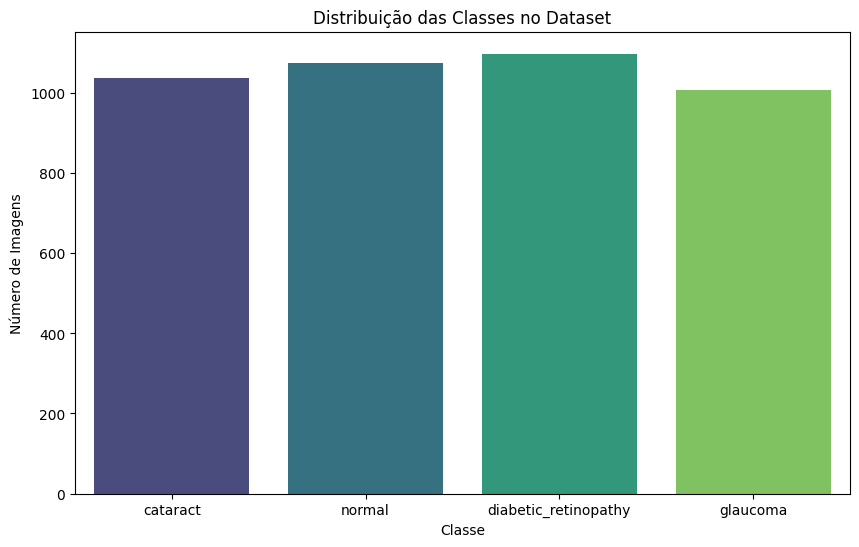

In [5]:
# Visualizar a distribuição das classes
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='rotulo', palette='viridis')
plt.title('Distribuição das Classes no Dataset')
plt.xlabel('Classe')
plt.ylabel('Número de Imagens')
plt.show()

### Análise da Distribuição das Classes

A base de dados apresenta uma distribuição balançeada ( distribuição aproximada de 25% para cada classe ), não possuindo uma disparidade significativa de amostras entre as classes. Portanto, o impacto da distribuição no desempenho do modelo não deve ser expressivo.


--- Exemplos de Imagens por Classe ---

Classe: cataract


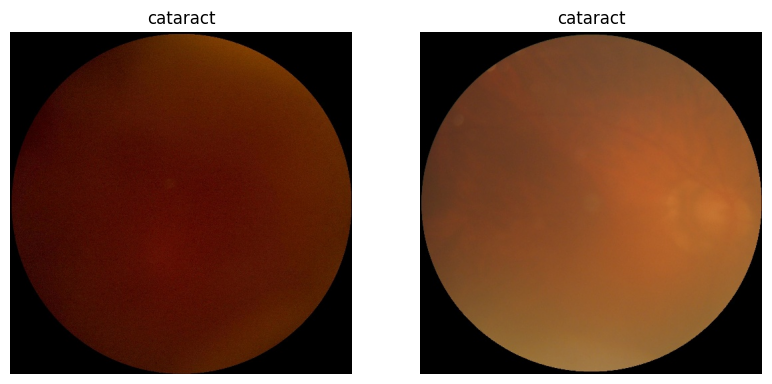


Classe: normal


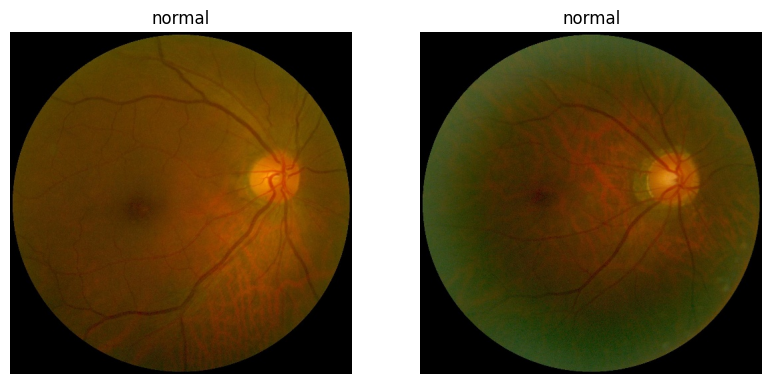


Classe: diabetic_retinopathy


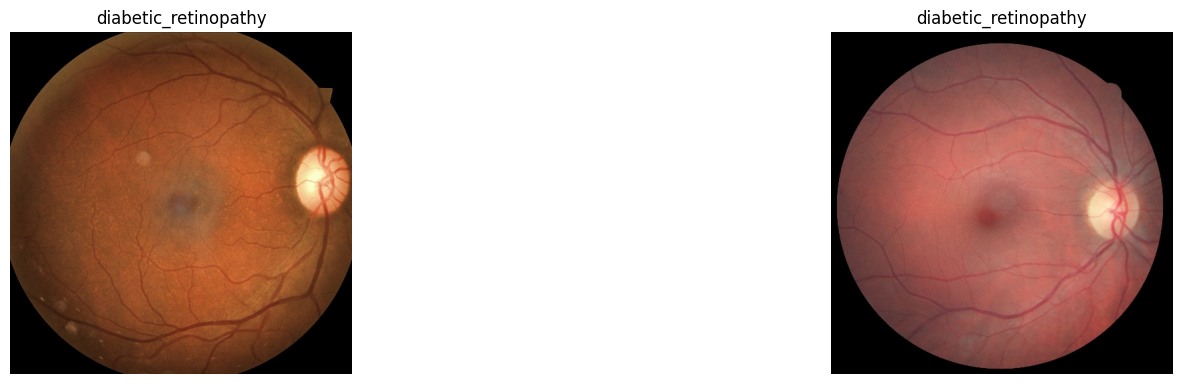


Classe: glaucoma


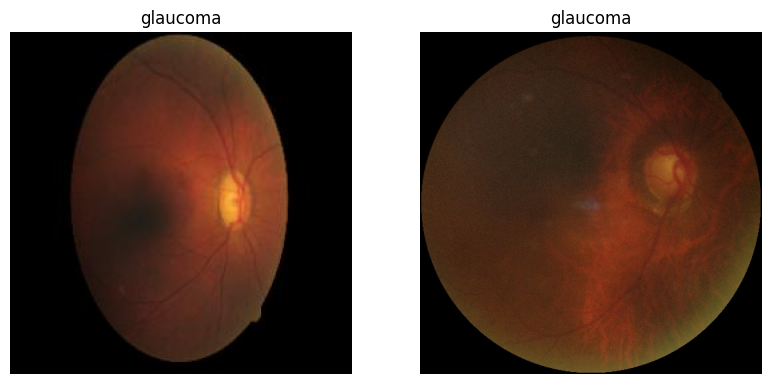

In [6]:
# Display representative samples from each class
print("\n--- Exemplos de Imagens por Classe ---")

for rotulo_classe in df['rotulo'].unique():
    print(f"\nClasse: {rotulo_classe}")
    # Seleciona aleatoriamente 3 imagens por classe para visualização
    amostras_classe = df[df['rotulo'] == rotulo_classe].sample(3, random_state=42)

    plt.figure(figsize=(15, 5))
    for i, row in amostras_classe.iterrows():
        caminho_img = row['caminho_arquivo']
        try:
            img = plt.imread(caminho_img)
            plt.subplot(1, 3, i % 3 + 1)
            plt.imshow(img)
            plt.title(rotulo_classe)
            plt.axis('off')
        except Exception as e:
            print(f"Não foi possível carregar a imagem {caminho_img}: {e}")
    plt.show()

## Dataset Splits
O dataset não possui divisões pré-definidas em treino, validação e teste.  
Essa etapa será realizada posteriormente de forma estratificada, garantindo que todas as classes estejam representadas proporcionalmente em cada subconjunto.


O dataset já está subdividido em 4 classes sendo:
- Catarata
- Normal
- Glaucoma
- Retinopatía Diabética


--- Avaliação de Qualidade das Imagens ---

Nitidez (Blur score):
count    4217.000000
mean      196.037787
std       180.645629
min         4.093784
25%        68.598015
50%       144.421172
75%       270.789482
max      1805.950764
Name: blur_score, dtype: float64

Brilho médio:
count    4217.000000
mean       78.915747
std        31.223560
min         5.191074
25%        56.113578
50%        74.192826
75%        97.486099
max       214.483269
Name: brightness, dtype: float64

Ruído (desvio padrão dos pixels):
count    4217.000000
mean       46.502844
std        16.052289
min         5.481131
25%        34.346150
50%        45.300652
75%        56.974887
max       103.547987
Name: noise, dtype: float64


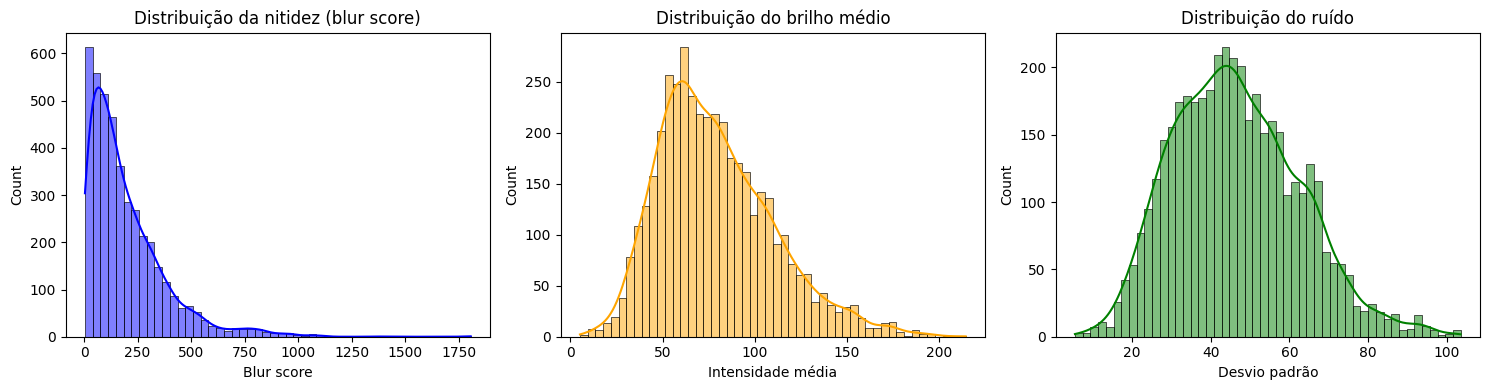

In [7]:
def blur_score(image_path):
    """Mede nitidez da imagem (variância do Laplaciano).
       Valores baixos indicam imagem borrada."""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    return cv2.Laplacian(img, cv2.CV_64F).var()

def brightness_score(image_path):
    """Mede brilho médio da imagem (0=escura, 255=clara)."""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    return np.mean(img)

def noise_score(image_path):
    """Mede nível de ruído (desvio padrão da intensidade dos pixels)."""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    return np.std(img)

df['blur_score'] = df['caminho_arquivo'].apply(blur_score)
df['brightness'] = df['caminho_arquivo'].apply(brightness_score)
df['noise'] = df['caminho_arquivo'].apply(noise_score)

print("\n--- Avaliação de Qualidade das Imagens ---")
print("\nNitidez (Blur score):")
print(df['blur_score'].describe())

print("\nBrilho médio:")
print(df['brightness'].describe())

print("\nRuído (desvio padrão dos pixels):")
print(df['noise'].describe())

# Histogramas
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
sns.histplot(df['blur_score'].dropna(), bins=50, kde=True, color="blue")
plt.title("Distribuição da nitidez (blur score)")
plt.xlabel("Blur score")

plt.subplot(1,3,2)
sns.histplot(df['brightness'].dropna(), bins=50, kde=True, color="orange")
plt.title("Distribuição do brilho médio")
plt.xlabel("Intensidade média")

plt.subplot(1,3,3)
sns.histplot(df['noise'].dropna(), bins=50, kde=True, color="green")
plt.title("Distribuição do ruído")
plt.xlabel("Desvio padrão")

plt.tight_layout()
plt.show()


# 4. Dataset splitting

In this section, you should split the dataset using the division provided by the dataset authors or the one widely adopted by the research community, if such a standard exists.

If no predefined split is available, you must create your own training, validation, and test subsets. In this case, carefully select a splitting strategy that aligns with both the nature of your task and the characteristics of the dataset. **Be sure to explicitly explain and justify your reasoning**, making clear why your chosen approach is appropriate.

### Divisão da Base de Dados
Fazendo o uso de divisão estratificada para manter a distribuição das classes e dividindo a base dados para validação cruzada com k folds = 5, escolhendo um dos folds para validação. Visando assim uma divisão para estimativas robustas dos modelos.

In [8]:
from sklearn.model_selection import StratifiedKFold

# Definir o número de folds para a validação cruzada
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# Adicionar uma coluna para o fold no DataFrame original
df['fold'] = -1

# Iterar sobre os folds e atribuir o número do fold a cada amostra
for fold, (train_index, val_index) in enumerate(skf.split(df['caminho_arquivo'], df['rotulo'])):
    df.loc[val_index, 'fold'] = fold

print(f"Dataset dividido em {n_splits} folds para validação cruzada.")
display(df.head())

# Informações de um fold
train_df = df[df['fold'] != 0]
val_df = df[df['fold'] == 0]

print(f"\nTamanho do conjunto de treino (Fold 0): {len(train_df)}")
print(f"Tamanho do conjunto de validação (Fold 0): {len(val_df)}")
display(train_df['rotulo'].value_counts())
display(val_df['rotulo'].value_counts())

Dataset dividido em 5 folds para validação cruzada.


,caminho_arquivo,rotulo,blur_score,brightness,noise,fold
0,/content/eye_diseases_dataset/cataract/_231_32...,cataract,629.372781,152.795349,87.409562,0
1,/content/eye_diseases_dataset/cataract/_383_41...,cataract,53.521580,62.663467,64.477763,4
2,/content/eye_diseases_dataset/cataract/_43_583...,cataract,209.252737,90.110077,54.568697,2
3,/content/eye_diseases_dataset/cataract/_60_707...,cataract,114.925077,81.628677,44.658259,1
4,/content/eye_diseases_dataset/cataract/_170_10...,cataract,626.878755,145.960297,81.437025,1



Tamanho do conjunto de treino (Fold 0): 3373
Tamanho do conjunto de validação (Fold 0): 844


,count
rotulo,
diabetic_retinopathy,879
normal,859
cataract,830
glaucoma,805


,count
rotulo,
diabetic_retinopathy,219
normal,215
cataract,208
glaucoma,202


# 5. Image Preprocessing

In this stage, you should apply preprocessing techniques tailored to your task. Start with fundamental steps such as resizing, padding, and format conversion to ensure consistency across the dataset.

Depending on the characteristics of your data and the requirements of the task, you may also consider additional techniques, such as normalization or scaling of pixel values, color space transformations (e.g., RGB to grayscale or HSV), contrast and brightness adjustment, noise reduction or filtering, among others.

In some cases, instead of tackling the full complexity of tasks such as object detection, segmentation, or OCR, *you may apply preprocessing steps to extract regions of interest and reframe the problem as a simpler classification task* (e.g., “target object vs. non-target object” in cropped patches), making subsequent baseline comparisons more feasible.

When deciding which strategies to adopt, **take into account the nature of the task, the characteristics of the dataset, the computational limitations of the hardware, and the specific models or approaches you plan to use**. Explicitly explain and justify your choices, making clear why each preprocessing step is appropriate in your context.

##O que foi feito:

Todas as imagens foram abertas em modo RGB para padronizar o espaço de cor.

Foram redimensionadas para 512×512 pixels, o tamanho predominante do dataset.

Imagens no formato .png e .jpeg foram convertidas para .jpg, com qualidade ajustada.

Esse passo garante consistência nas entradas do modelo, evitando problemas com diferentes tamanhos ou formatos de imagem. O redimensionamento facilita o treinamento, enquanto a padronização em JPEG simplifica o pipeline e reduz possíveis incompatibilidades.

In [10]:
input_folder = "/content/eye_diseases_dataset"
output_folder = "/content/eye_diseases_dataset_processed"

# Criar pasta de saída se não existir
os.makedirs(output_folder, exist_ok=True)

# Tamanho padrão para o modelo
target_size = (512, 512)

# Processamento da Etapa 1
for filename in os.listdir(input_folder):

    class_dir = os.path.join(input_folder, filename)
    if os.path.isdir(class_dir):
        output_class_dir = os.path.join(output_folder, filename)
        os.makedirs(output_class_dir, exist_ok=True)

        for image_filename in os.listdir(class_dir):
            if image_filename.lower().endswith((".png", ".jpg", ".jpeg")):
                # Abrir imagem e converter para RGB
                img_path = os.path.join(class_dir, image_filename)
                img = Image.open(img_path).convert("RGB")

                # Redimensionar sem padding
                img_resized = img.resize(target_size, Image.LANCZOS)

                # Salvar em JPG
                output_path = os.path.join(output_class_dir, os.path.splitext(image_filename)[0] + ".jpg")
                img_resized.save(output_path, "JPEG", quality=100)

###O que foi feito:

Foi aplicado um aumento leve de brilho e contraste (1.1×).

As imagens foram processadas com filtro gaussiano 3×3, reduzindo ruído e suavizando imperfeições.

Os pixels foram normalizados para [0,1], padronizando a escala de valores.

As imagens foram salvas novamente em formato JPG.

Essas etapas melhoram a qualidade visual e reduzem problemas comuns do dataset (variação de iluminação e ruído). O ajuste de brilho/contraste realça detalhes úteis para detecção de doenças oculares. A normalização facilita o aprendizado das redes neurais, acelerando a convergência do modelo.

In [9]:
input_folder = "/content/eye_diseases_dataset_processed"

for class_name in os.listdir(input_folder):
    class_dir = os.path.join(input_folder, class_name)
    if os.path.isdir(class_dir):

        for filename in os.listdir(class_dir):
            if filename.lower().endswith(".jpg"):
                img_path = os.path.join(class_dir, filename)

                # Abrir imagem
                img = Image.open(img_path).convert("RGB")

                # Ajuste de brilho e contraste
                enhancer = ImageEnhance.Brightness(img)
                img = enhancer.enhance(1.1)  # leve aumento de brilho
                enhancer = ImageEnhance.Contrast(img)
                img = enhancer.enhance(1.1)  # leve aumento de contraste

                # Converter para array NumPy para filtragem
                img_np = np.array(img)
                # Redução de ruído (filtro gaussiano)
                img_np = cv2.GaussianBlur(img_np, (3,3), 0)

                # Normalização para [0,1]
                img_np = img_np / 255.0

                # Converter de volta para PIL Image antes de salvar
                img_processed = Image.fromarray((img_np * 255).astype(np.uint8))

                # Sobrescreve a própria imagem
                img_processed.save(img_path, "JPEG", quality=100)

# 6. Traditional approach

In this section, you should implement a baseline solution using **traditional image processing and machine learning techniques**.

Begin by extracting [handcrafted] features with classical methods that are suitable for your task, such as color histograms, texture descriptors (e.g., LBP), or gradient-based features (e.g., HOG).
*   You are encouraged to search for and experiment with other  descriptors from the literature that may be more relevant to your dataset or problem.

To improve robustness, consider combining multiple feature types through concatenation or feature fusion. Apply feature scaling or normalization where appropriate to ensure compatibility with the chosen classifiers.

Next, train at least three different traditional classifiers (e.g., SVM, Random Forest, KNN) on the extracted features and evaluate their performance using relevant metrics for your task. Perform an **ablation study** by comparing the results obtained with different feature sets (individually and in combination) to better understand their contribution to performance.

Naturally, provide a clear justification for each design choice, explaining why it is appropriate for your specific problem. Also, analyze and discuss the results in detail, highlighting patterns, strengths, and limitations, as well as insights gained from the ablation study.

### Abordagem Tradicional
o uso do descritor de textura LBP se prova valioso visto que a textura de retinas pode variar de acordo com o problema (e.g. catarata)

In [10]:
# LBP

diretorio_dataset_processed = '/content/eye_diseases_dataset_processed'

# Lista todos os caminhos das imagens processadas e cria um DataFrame temporário
caminhos_imagens_processed = []
rotulos_processed = []
for nome_classe in os.listdir(diretorio_dataset_processed):
    diretorio_classe = os.path.join(diretorio_dataset_processed, nome_classe)
    if os.path.isdir(diretorio_classe):
        for nome_arquivo in os.listdir(diretorio_classe):
            if nome_arquivo.lower().endswith(('.jpg', '.jpeg', '.png')):
                caminhos_imagens_processed.append(os.path.join(diretorio_classe, nome_arquivo))
                rotulos_processed.append(nome_classe)

df_processed = pd.DataFrame({'caminho_arquivo': caminhos_imagens_processed, 'rotulo': rotulos_processed})

print("DataFrame para o dataset processado criado com sucesso!")

# Extraindo features LPB e salvando em um Dataframe
lbp_features = []
labels = []
p, r = 8, 1
lbp_method = "nri_uniform"

for index, row in df_processed.iterrows():
    img_path = row['caminho_arquivo']
    label = row['rotulo']

    try:
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is not None:
            lbp = local_binary_pattern(img, P=p, R=r, method=lbp_method)
            n_bins = int(lbp.max() + 1)
            hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
            lbp_features.append(hist)
            labels.append(label)
        else:
            print(f"Could not read image: {img_path}")
    except Exception as e:
        print(f"Error processing image {img_path}: {e}")

df_lbp = pd.DataFrame(lbp_features)
df_lbp['label'] = labels

print("\nDataFrame com features LBP e rótulos criado com sucesso!")
display(df_lbp.head())

# Separando df_lbp em 5 folds
from sklearn.model_selection import StratifiedKFold

# Definir o número de folds para a validação cruzada
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# Adicionar uma coluna para o fold no DataFrame original
df_lbp['fold'] = -1

# Iterar sobre os folds e atribuir o número do fold a cada amostra
for fold, (train_index, val_index) in enumerate(skf.split(df_lbp, df_lbp['label'])):
    df_lbp.loc[val_index, 'fold'] = fold

print(f"\nDataset LBP dividido em {n_splits} folds para validação cruzada.")
display(df_lbp.head())

DataFrame para o dataset processado criado com sucesso!

DataFrame com features LBP e rótulos criado com sucesso!


,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,label
0,0.007725,0.003906,0.000019,0.001385,0.000027,0.001427,0.000015,0.003857,0.000072,0.000641,...,0.000599,0.036102,0.000553,0.007004,0.000393,0.003273,0.000374,0.647495,0.020161,cataract
1,0.005844,0.002758,0.000015,0.002644,0.000019,0.002834,0.000031,0.002602,0.000046,0.000317,...,0.000526,0.009060,0.000511,0.009026,0.000500,0.010075,0.000496,0.704472,0.021263,cataract
2,0.008308,0.003967,0.000099,0.005142,0.000050,0.002960,0.000042,0.001904,0.000031,0.000439,...,0.000557,0.007156,0.000832,0.025616,0.000938,0.014648,0.000660,0.555817,0.027504,cataract
3,0.011196,0.005814,0.000103,0.005882,0.000099,0.005795,0.000061,0.004757,0.000076,0.000984,...,0.001144,0.015896,0.001511,0.019676,0.001328,0.018726,0.001507,0.392872,0.046635,cataract
4,0.004635,0.001568,0.000050,0.001690,0.000069,0.002228,0.000084,0.001942,0.000050,0.000397,...,0.000584,0.004002,0.000534,0.003292,0.000549,0.005394,0.000568,0.774857,0.013721,cataract



Dataset LBP dividido em 5 folds para validação cruzada.


,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,label,fold
0,0.007725,0.003906,0.000019,0.001385,0.000027,0.001427,0.000015,0.003857,0.000072,0.000641,...,0.036102,0.000553,0.007004,0.000393,0.003273,0.000374,0.647495,0.020161,cataract,0
1,0.005844,0.002758,0.000015,0.002644,0.000019,0.002834,0.000031,0.002602,0.000046,0.000317,...,0.009060,0.000511,0.009026,0.000500,0.010075,0.000496,0.704472,0.021263,cataract,4
2,0.008308,0.003967,0.000099,0.005142,0.000050,0.002960,0.000042,0.001904,0.000031,0.000439,...,0.007156,0.000832,0.025616,0.000938,0.014648,0.000660,0.555817,0.027504,cataract,2
3,0.011196,0.005814,0.000103,0.005882,0.000099,0.005795,0.000061,0.004757,0.000076,0.000984,...,0.015896,0.001511,0.019676,0.001328,0.018726,0.001507,0.392872,0.046635,cataract,1
4,0.004635,0.001568,0.000050,0.001690,0.000069,0.002228,0.000084,0.001942,0.000050,0.000397,...,0.004002,0.000534,0.003292,0.000549,0.005394,0.000568,0.774857,0.013721,cataract,1


Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END .....................................C=0.1, gamma=1; total time=   0.9s
[CV] END .....................................C=0.1, gamma=1; total time=   0.9s
[CV] END .....................................C=0.1, gamma=1; total time=   0.9s
[CV] END .....................................C=0.1, gamma=1; total time=   0.9s
[CV] END .....................................C=0.1, gamma=1; total time=   0.9s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.5s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.6s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.7s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.5s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.6s
[CV] END .......................................C=1, gamma=1; total time=   2.1s
[CV] END .......................................C

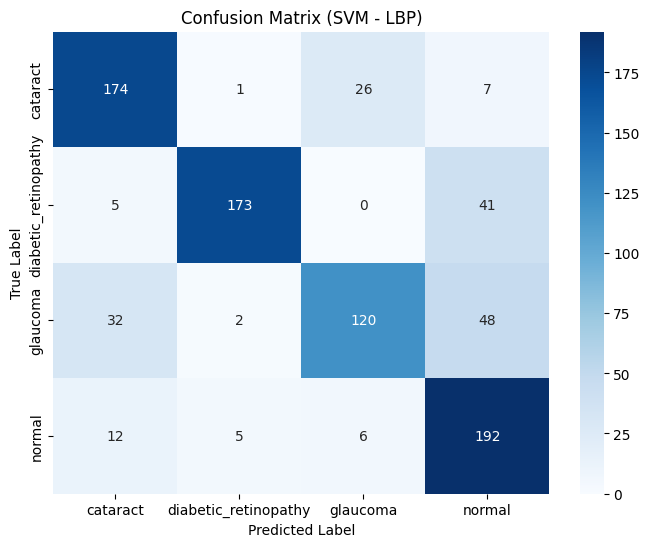

In [11]:
# SVM - LBP

# Separate features (X) and labels (y)
X = df_lbp.drop(['label','fold'], axis=1)
y = df_lbp['label']


train_fold_id = 0 # Use fold 0 as the validation set for this example
X_train = X[df_lbp['fold'] != train_fold_id]
y_train = y[df_lbp['fold'] != train_fold_id]
X_test = X[df_lbp['fold'] == train_fold_id]
y_test = y[df_lbp['fold'] == train_fold_id]


# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the parameter grid for GridSearchCV
param_grid = {'C': [0.1, 1],
'gamma': [1,  0.01]}

# Create a GridSearchCV object
grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=2, cv=5)

# Fit the model using the scaled training data
grid.fit(X_train_scaled, y_train)

# Print the best parameters found
print("Melhores parâmetros encontrados:")
print(grid.best_params_)

# Evaluate the model on the scaled test data
grid_predictions = grid.predict(X_test_scaled)

# Print classification report and confusion matrix
print("\nResultados no conjunto de teste:")
print(classification_report(y_test, grid_predictions))

# Generate and plot the confusion matrix
cm = confusion_matrix(y_test, grid_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=grid.classes_, yticklabels=grid.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (SVM - LBP)')
plt.show()

In [ ]:
# RF - LBP

# Scale the features (Scaling is less critical for Tree-based models but still good practice)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the parameter grid for GridSearchCV for RandomForestClassifier
param_grid = {
    'n_estimators': [100, 200], # Número de árvores na floresta
    'max_depth': [10, 20], # Profundidade máxima da árvore
    'min_samples_split': [2, 5], # Número mínimo de amostras para dividir um nó interno
    'min_samples_leaf': [1, 2]    # Número mínimo de amostras em um nó folha
}

# Create a GridSearchCV object
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, refit=True, verbose=2, cv=5, n_jobs=-1) # Use n_jobs=-1 for parallel processing

# Fit the model using the scaled training data
grid.fit(X_train_scaled, y_train)

# Print the best parameters found
print("Melhores parâmetros encontrados:")
print(grid.best_params_)

# Evaluate the model on the scaled test data
grid_predictions = grid.predict(X_test_scaled)

# Print classification report and confusion matrix
print("\nResultados no conjunto de teste:")
print(classification_report(y_test, grid_predictions))

# Generate and plot the confusion matrix
cm = confusion_matrix(y_test, grid_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=grid.classes_, yticklabels=grid.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Random Forest - LBP)')
plt.show()

Fitting 5 folds for each of 8 candidates, totalling 40 fits


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.76401451 0.77379756 0.76846599 0.77498626        nan 0.77261325
        nan 0.77735795]
  warnings.warn(


Melhores parâmetros encontrados:
{'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}

Resultados no conjunto de teste:
                      precision    recall  f1-score   support

            cataract       0.83      0.77      0.80       208
diabetic_retinopathy       0.94      0.90      0.92       219
            glaucoma       0.67      0.63      0.65       202
              normal       0.70      0.82      0.76       215

            accuracy                           0.78       844
           macro avg       0.79      0.78      0.78       844
        weighted avg       0.79      0.78      0.78       844



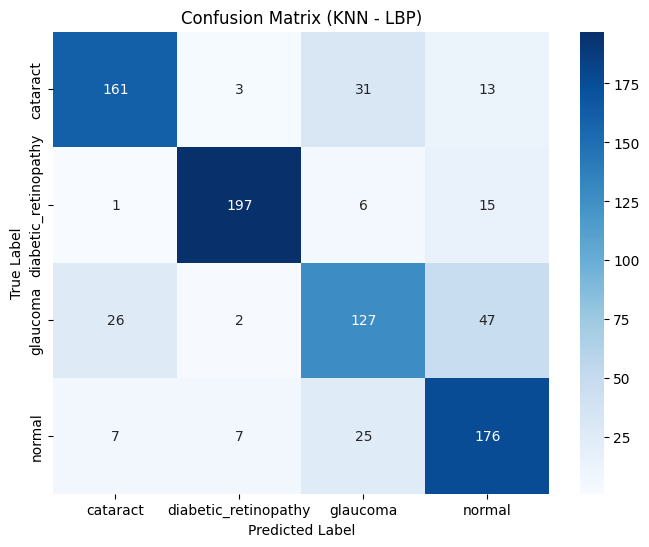

In [13]:
# KNN - LBP

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the parameter grid for GridSearchCV for KNeighborsClassifier
param_grid = {
    'n_neighbors': [3, 5], # Number of neighbors to use
    'weights': ['uniform', 'distance'], # Weight function used in prediction
    'metric': ['euclidean', 'manhattan'] # Distance metric
}

# Create a GridSearchCV object
grid = GridSearchCV(KNeighborsClassifier(), param_grid, refit=True, verbose=2, cv=5, n_jobs=-1) # Use n_jobs=-1 for parallel processing

# Fit the model using the scaled training data
grid.fit(X_train_scaled, y_train)

# Print the best parameters found
print("Melhores parâmetros encontrados:")
print(grid.best_params_)

# Evaluate the model on the scaled test data
grid_predictions = grid.predict(X_test_scaled)

# Print classification report and confusion matrix
print("\nResultados no conjunto de teste:")
print(classification_report(y_test, grid_predictions))

# Generate and plot the confusion matrix
cm = confusion_matrix(y_test, grid_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=grid.classes_, yticklabels=grid.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (KNN - LBP)')
plt.show()

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END .....................................C=0.1, gamma=1; total time=   0.3s
[CV] END .....................................C=0.1, gamma=1; total time=   0.3s
[CV] END .....................................C=0.1, gamma=1; total time=   0.3s
[CV] END .....................................C=0.1, gamma=1; total time=   0.3s
[CV] END .....................................C=0.1, gamma=1; total time=   0.6s
[CV] END ..................................C=0.1, gamma=0.01; total time=   1.1s
[CV] END ..................................C=0.1, gamma=0.01; total time=   1.1s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.6s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.5s
[CV] END ..................................C=0.1, gamma=0.01; total time=   0.3s
[CV] END .......................................C=1, gamma=1; total time=   0.3s
[CV] END .......................................C

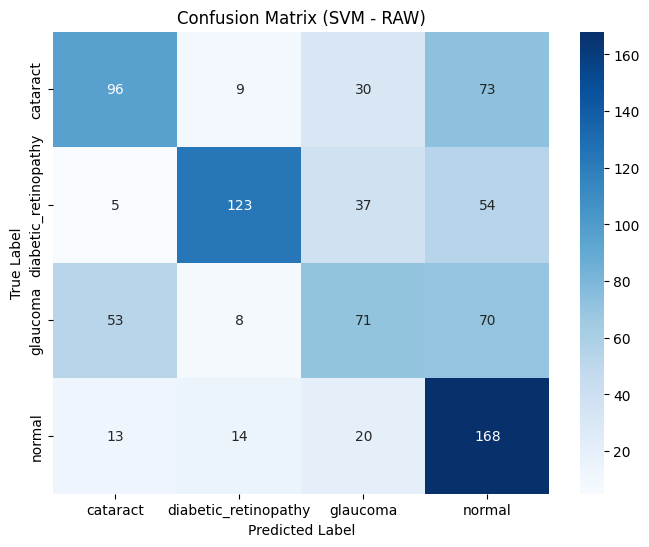

In [11]:
# SVM - RAW

# Separate features (X) and labels (y)
# Assuming 'df' contains the raw image data or features extracted directly from raw images
# and 'fold' column is already present in 'df' from previous steps

# Drop non-feature columns ('label' and 'fold') to get features X
X = df.drop(['rotulo', 'fold', 'caminho_arquivo'], axis=1) # Use 'rotulo' as the label column name in df and exclude 'caminho_arquivo'
y = df['rotulo'] # Use 'rotulo' as the label column name in df


train_fold_id = 0 # Use fold 0 as the validation set for this example
X_train = X[df['fold'] != train_fold_id]
y_train = y[df['fold'] != train_fold_id]
X_test = X[df['fold'] == train_fold_id]
y_test = y[df['fold'] == train_fold_id]

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the parameter grid for GridSearchCV
param_grid = {'C': [0.1, 1],
'gamma': [1,  0.01]}

# Create a GridSearchCV object
grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=2, cv=5)

# Fit the model using the scaled training data
grid.fit(X_train_scaled, y_train)

# Print the best parameters found
print("Melhores parâmetros encontrados:")
print(grid.best_params_)

# Evaluate the model on the scaled test data
grid_predictions = grid.predict(X_test_scaled)

# Print classification report and confusion matrix
print("\nResultados no conjunto de teste:")
print(classification_report(y_test, grid_predictions))

# Generate and plot the confusion matrix
cm = confusion_matrix(y_test, grid_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=grid.classes_, yticklabels=grid.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (SVM - RAW)')
plt.show()

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Melhores parâmetros encontrados:
{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}

Resultados no conjunto de teste:
                      precision    recall  f1-score   support

            cataract       0.60      0.52      0.56       208
diabetic_retinopathy       0.86      0.65      0.74       219
            glaucoma       0.52      0.50      0.51       202
              normal       0.50      0.71      0.59       215

            accuracy                           0.60       844
           macro avg       0.62      0.59      0.60       844
        weighted avg       0.62      0.60      0.60       844



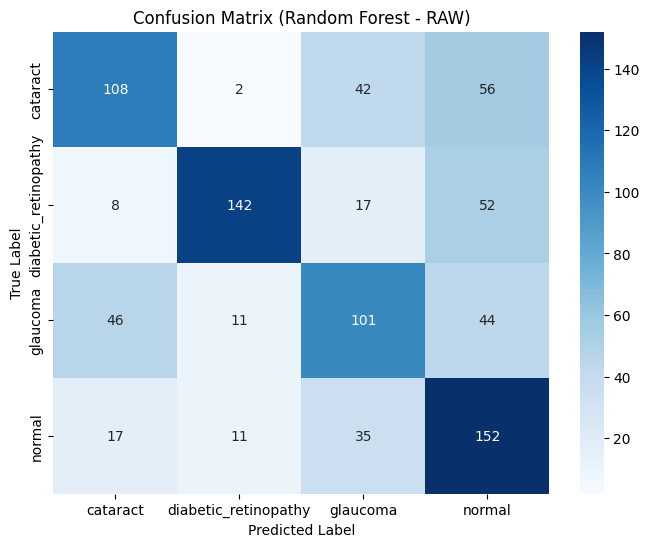

In [12]:
# RF - RAW

# Separate features (X) and labels (y)
# Assuming 'df' contains the raw image data or features extracted directly from raw images
# and 'fold' column is already present in 'df' from previous steps

# Drop non-feature columns ('label' and 'fold') to get features X
X = df.drop(['rotulo', 'fold', 'caminho_arquivo'], axis=1) # Use 'rotulo' as the label column name in df and exclude 'caminho_arquivo'
y = df['rotulo'] # Use 'rotulo' as the label column name in df

train_fold_id = 0 # Use fold 0 as the validation set for this example
X_train = X[df['fold'] != train_fold_id]
y_train = y[df['fold'] != train_fold_id]
X_test = X[df['fold'] == train_fold_id]
y_test = y[df['fold'] == train_fold_id]

# Scale the features (Scaling is less critical for Tree-based models but still good practice)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the parameter grid for GridSearchCV for RandomForestClassifier
param_grid = {
    'n_estimators': [100, 200], # Número de árvores na floresta
    'max_depth': [10, 20], # Profundidade máxima da árvore
    'min_samples_split': [2, 5], # Número mínimo de amostras para dividir um nó interno
    'min_samples_leaf': [1, 2]    # Número mínimo de amostras em um nó folha
}

# Create a GridSearchCV object
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, refit=True, verbose=2, cv=5, n_jobs=-1) # Use n_jobs=-1 for parallel processing

# Fit the model using the scaled training data
grid.fit(X_train_scaled, y_train)

# Print the best parameters found
print("Melhores parâmetros encontrados:")
print(grid.best_params_)

# Evaluate the model on the scaled test data
grid_predictions = grid.predict(X_test_scaled)

# Print classification report and confusion matrix
print("\nResultados no conjunto de teste:")
print(classification_report(y_test, grid_predictions))

# Generate and plot the confusion matrix
cm = confusion_matrix(y_test, grid_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=grid.classes_, yticklabels=grid.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (Random Forest - RAW)')
plt.show()

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Melhores parâmetros encontrados:
{'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}

Resultados no conjunto de teste:
                      precision    recall  f1-score   support

            cataract       0.51      0.50      0.51       208
diabetic_retinopathy       0.79      0.64      0.71       219
            glaucoma       0.44      0.48      0.46       202
              normal       0.47      0.53      0.50       215

            accuracy                           0.54       844
           macro avg       0.55      0.54      0.54       844
        weighted avg       0.55      0.54      0.54       844



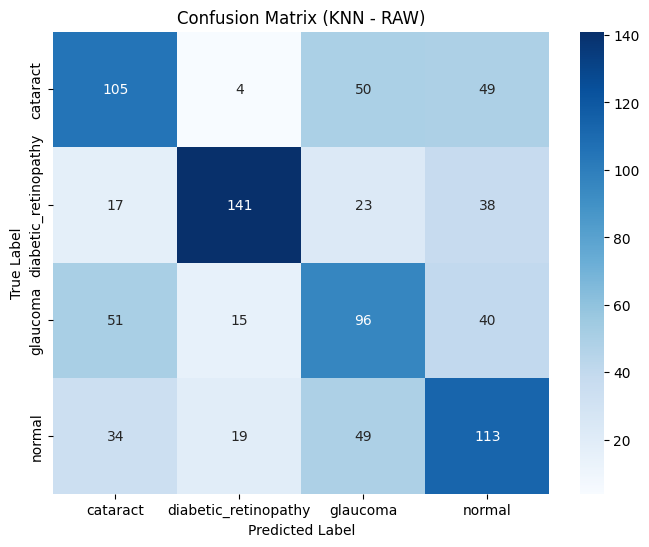

In [13]:
# KNN - RAW

# Separate features (X) and labels (y)
# Assuming 'df' contains the raw image data or features extracted directly from raw images
# and 'fold' column is already present in 'df' from previous steps

# Drop non-feature columns ('label' and 'fold') to get features X
X = df.drop(['rotulo', 'fold', 'caminho_arquivo'], axis=1) # Use 'rotulo' as the label column name in df and exclude 'caminho_arquivo'
y = df['rotulo'] # Use 'rotulo' as the label column name in df

train_fold_id = 0 # Use fold 0 as the validation set for this example
X_train = X[df['fold'] != train_fold_id]
y_train = y[df['fold'] != train_fold_id]
X_test = X[df['fold'] == train_fold_id]
y_test = y[df['fold'] == train_fold_id]

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the parameter grid for GridSearchCV for KNeighborsClassifier
param_grid = {
    'n_neighbors': [3, 5], # Number of neighbors to use
    'weights': ['uniform', 'distance'], # Weight function used in prediction
    'metric': ['euclidean', 'manhattan'] # Distance metric
}

# Create a GridSearchCV object
grid = GridSearchCV(KNeighborsClassifier(), param_grid, refit=True, verbose=2, cv=5, n_jobs=-1) # Use n_jobs=-1 for parallel processing

# Fit the model using the scaled training data
grid.fit(X_train_scaled, y_train)

# Print the best parameters found
print("Melhores parâmetros encontrados:")
print(grid.best_params_)

# Evaluate the model on the scaled test data
grid_predictions = grid.predict(X_test_scaled)

# Print classification report and confusion matrix
print("\nResultados no conjunto de teste:")
print(classification_report(y_test, grid_predictions))

# Generate and plot the confusion matrix
cm = confusion_matrix(y_test, grid_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=grid.classes_, yticklabels=grid.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (KNN - RAW)')
plt.show()

# Checkpoint (Submission)

1. Save this report as a Jupyter Notebook (`.ipynb`);
2. Export a copy of the report as a PDF file (`.pdf`), ensuring that all code cells are executed and their outputs are visible in the exported document;
3. Compress all the files (the Jupyter Notebook, PDF) into a single ZIP archive (`EquipeXX.zip`);
4. Upload the ZIP file to Canvas.

# 7. Data augmentation (**post-checkpoint!**)

In this section, you should **design a data augmentation strategy** to increase both the diversity and robustness of your training data. Consider applying a variety of techniques, including but not limited to:

- Color adjustments  
- Rotation and scaling  
- Horizontal/vertical flipping  
- Blurring (e.g., Gaussian or motion blur)  
- Additive noise  
- Compression artifacts  
- Geometric distortions (e.g., perspective or warping)  
- Cropping  

You are encouraged to explore specialized libraries such as **Albumentations**, which provide efficient and flexible augmentation pipelines.  

Clearly specify whether augmentation will be applied **offline** (pre-generated before training) or **online** (generated dynamically during training). When dealing with class imbalance, adopt **targeted augmentation strategies** to increase the representation of minority classes.  

Make sure to **justify** your design choices. Discuss how each selected augmentation technique relates to the **requirements of the task** and the **characteristics of the dataset**, highlighting why your decisions are appropriate.

In [ ]:
# use as many code and text cells as needed

# 8. Deep learning approach (**post-checkpoint!**)

In this section, you should leverage **deep learning models** to address your task. You may explore one or both of the following strategies:

1. **Training from scratch** – train a neural network architecture directly on your dataset;  
2. **Transfer learning** – leverage pre-trained models, either by:
   - Freezing the feature extractor and training only the classifier layers; or
   - Performing fine-tuning, updating some or all pre-trained layers.

Consider well-established model families such as EfficientNet, MobileNet, ResNet, VGG, and [efficient] Transformer-based architectures, choosing those most appropriate given your **task requirements** and **computational constraints**.  

To optimize performance, experiment with key hyperparameters (e.g., optimizer, initial learning rate, batch size) and incorporate adaptive training techniques, such as:  
- Learning rate schedulers (e.g., *ReduceLROnPlateau*);
- Early stopping mechanisms to prevent overfitting.

You must train **at least three distinct models** and evaluate their performance using **relevant quantitative metrics**. Compare the outcomes with the best-performing traditional approach (from Step 6). Additionally, include **qualitative analysis** (e.g., visualization of predictions, error inspection, or case studies) to better understand model behavior beyond numerical results.

Whenever possible, conduct an **ablation study** to isolate the contribution of specific design choices (e.g., augmentation strategy, training from scratch vs. transfer learning, etc.) to justify your final pipeline.

In [ ]:
# use as many code and text cells as needed

# Digest (**post-checkpoint!**)

In this section, you should **briefly summarize the main findings** of your project. Additionally, provide a **critical reflection** on your work and the effort invested throughout the module. Highlight the aspects you believe were handled successfully, as well as those that, in hindsight, you would approach differently.

As part of this reflection, consider whether the outcomes and lessons learned from this project contribute meaningfully to your overall **academic development** and to your **readiness for professional or postgraduate pursuits after graduation**.

While this digest **must contain at least 2,500 characters**, it is intended solely for self-reflection purposes and **will not be considered in the formal evaluation of your work**.

```
Add your text here.
```

# Final Steps (Submission)

1. Save the complete report (including all steps from Step 1 onward) as a Jupyter Notebook (`.ipynb`);
2. Export a copy of the report as a PDF file (`.pdf`), ensuring that all code cells are executed and their outputs are visible in the exported document;
3. Compress all the files (the Jupyter Notebook, PDF) into a single ZIP archive (`EquipeXX.zip`);
4. Upload the ZIP file to Canvas.